# Módulo Visualização de Dados

Leia o arquivo `ecommerce_preparados.csv` dentro de um dataframe, faça uma análise detalhada e crie: histograma, dispersão, mapa de calor, barra, pizza, densidade e regressão, com títulos nos gráficos e eixos e códigos comentados.

In [1]:
# Conecta ao Google Drive (apenas no Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CAMINHO = '/content/drive/MyDrive/DADOS/ecommerce_preparados.csv'
except ImportError:
    # Execução local: arquivo na pasta dados/
    CAMINHO = 'dados/ecommerce_preparados.csv'

In [2]:
# Bibliotecas de manipulação e visualização
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Estilo visual padrão para todos os gráficos
sns.set(style='whitegrid', palette='pastel')

In [3]:
# Leitura da base
df = pd.read_csv(CAMINHO)
df.head()

,Unnamed: 0,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,...,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,0,Pijama Cirurgico Scrub Roupa Privativa Hospit...,4.0,273.0,NaN,toronto uniformes profissionais,poliéster,Sem gênero,não definido,"Preço justo , bem feito acabamento ok. Única s...",...,0.629630,0.029969,NaN,0.100645,781,122,1,1000.0,0.002274,0.117326
1,1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,...,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
2,2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,...,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
3,3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...",...,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
4,4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,...,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466


## Análise exploratória

In [4]:
# Estrutura: tipos de dados e valores ausentes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2199 entries, 0 to 2198
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           2199 non-null   int64  
 1   Título               2199 non-null   str    
 2   Nota                 1559 non-null   float64
 3   N_Avaliações         1559 non-null   float64
 4   Desconto             874 non-null    float64
 5   Marca                2199 non-null   str    
 6   Material             1332 non-null   str    
 7   Gênero               2120 non-null   str    
 8   Temporada            2199 non-null   str    
 9   Review1              1515 non-null   str    
 10  Review2              1354 non-null   str    
 11  Review3              1233 non-null   str    
 12  Qtd_Vendidos         2199 non-null   str    
 13  Preço                1964 non-null   float64
 14  Nota_MinMax          1559 non-null   float64
 15  N_Avaliações_MinMax  1559 non-null   float64
 16 

In [5]:
# Colunas originais de interesse (excluímos as versões _MinMax, _Cod e _Freq, que são transformações das mesmas variáveis)
COLS_NUM = ['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Cod']

# Estatísticas descritivas
df[COLS_NUM].describe().round(2)

,Nota,N_Avaliações,Desconto,Preço,Qtd_Vendidos_Cod
count,1559.00,1559.00,874.00,1964.00,1973.00
mean,4.56,204.06,15.46,102.71,728.04
std,0.36,578.46,10.93,69.98,3621.82
min,2.30,1.00,5.00,10.88,0.00
25%,4.40,8.00,8.00,50.19,5.00
50%,4.60,27.00,11.00,78.97,50.00
75%,4.80,119.50,20.00,139.15,100.00
max,5.00,9077.00,66.00,597.30,50000.00


In [6]:
# Percentual de valores ausentes por variável
(df[COLS_NUM].isna().mean() * 100).round(1)

Nota                29.1
N_Avaliações        29.1
Desconto            60.3
Preço               10.7
Qtd_Vendidos_Cod    10.3
dtype: float64

**Principais observações:** a base tem 2.199 produtos. `Desconto` tem cerca de 60% de valores ausentes (produtos sem desconto). O preço mediano é ~R$ 79, mas há produtos de até ~R$ 597. A nota média é alta (4,56), e `N_Avaliações` e `Qtd_Vendidos_Cod` são muito assimétricas: poucos produtos concentram a maior parte das vendas.

In [7]:
def configurar_eixos(titulo, xlabel=None, ylabel=None):
    """Aplica título e rótulos de eixo padronizados e exibe o gráfico.

    Parâmetros
    ----------
    titulo : str
        Título do gráfico.
    xlabel : str, opcional
        Rótulo do eixo X.
    ylabel : str, opcional
        Rótulo do eixo Y.
    """
    plt.title(titulo, fontsize=14, fontweight='bold')
    if xlabel:
        plt.xlabel(xlabel)
    if ylabel:
        plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 1. Histograma — distribuição dos preços

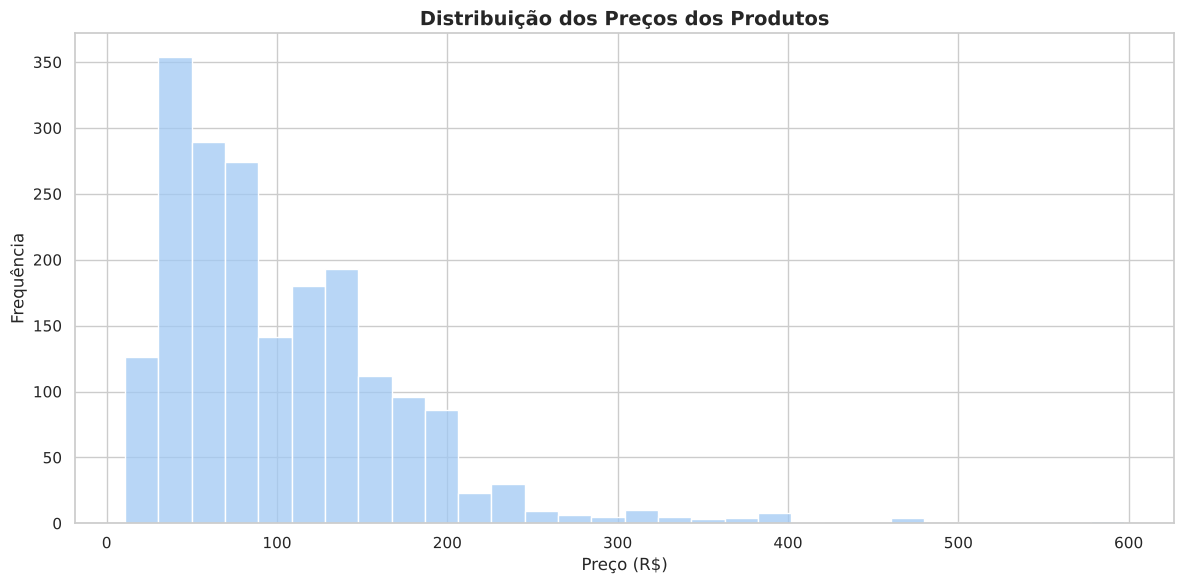

In [8]:
# Histograma do preço: mostra em quais faixas se concentra a maioria dos produtos
plt.figure(figsize=(12, 6))
sns.histplot(df['Preço'], bins=30)
configurar_eixos('Distribuição dos Preços dos Produtos', 'Preço (R$)', 'Frequência')

A distribuição é assimétrica à direita: a maior parte dos produtos custa entre R$ 50 e R$ 140, com uma cauda de itens mais caros.

## 2. Dispersão — preço × quantidade vendida

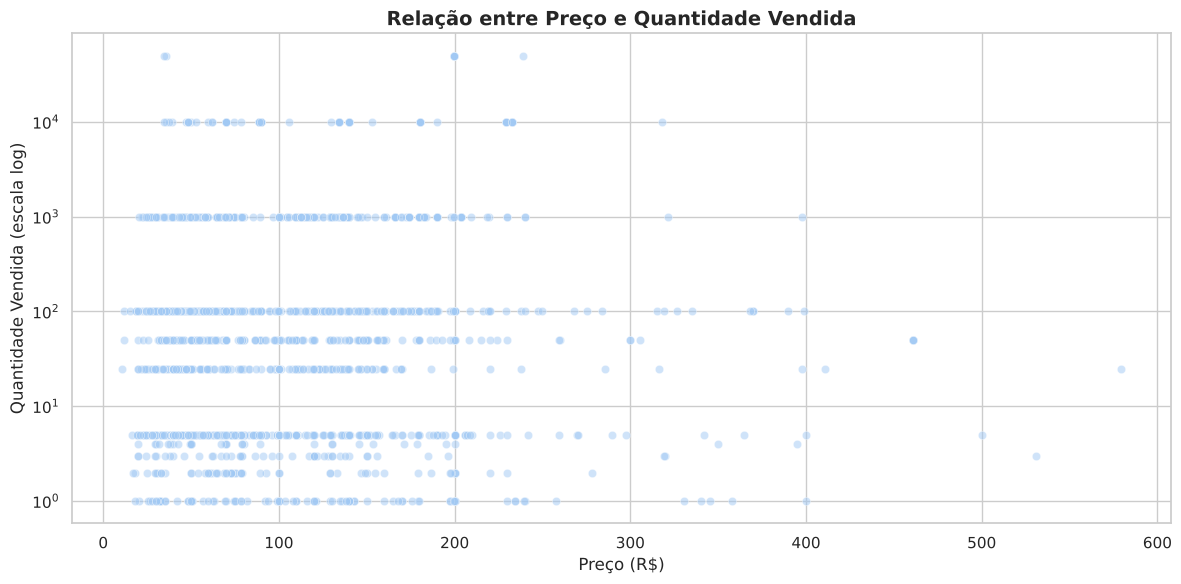

In [9]:
# Dispersão: verifica se produtos mais baratos vendem mais
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Preço', y='Qtd_Vendidos_Cod', alpha=0.5)
plt.yscale('log')  # escala log porque as vendas variam de 0 a 50.000
configurar_eixos('Relação entre Preço e Quantidade Vendida', 'Preço (R$)', 'Quantidade Vendida (escala log)')

Não há relação clara entre preço e volume de vendas (correlação ≈ 0,08): produtos de todas as faixas de preço vendem pouco ou muito.

## 3. Mapa de calor — correlações

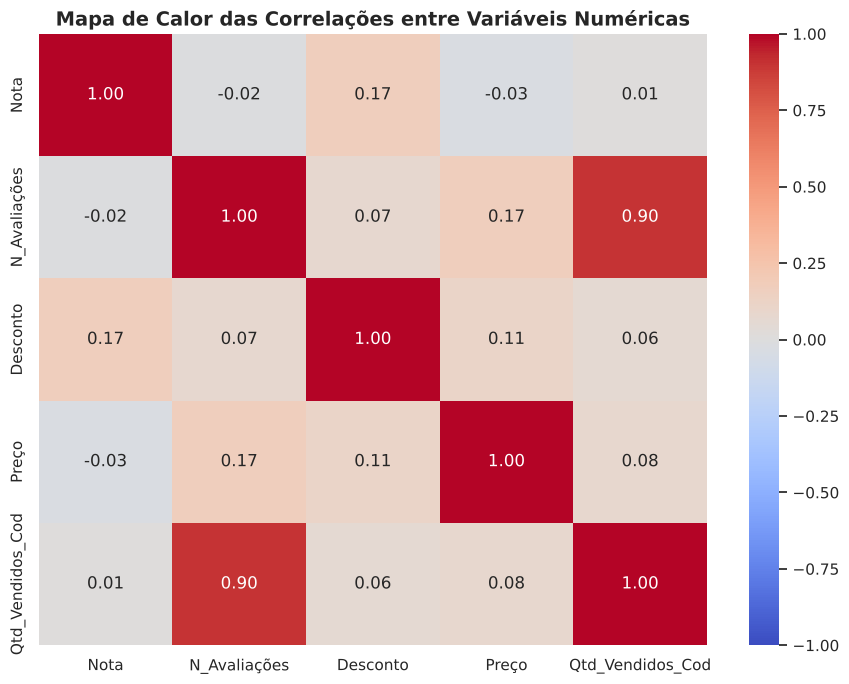

In [10]:
# Matriz de correlação apenas das variáveis originais, evitando colunas redundantes
plt.figure(figsize=(9, 7))
sns.heatmap(df[COLS_NUM].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
configurar_eixos('Mapa de Calor das Correlações entre Variáveis Numéricas')

O destaque é a forte correlação entre número de avaliações e quantidade vendida (0,90). As demais relações são fracas; o desconto tem leve associação positiva com a nota (0,17).

## 4. Barras — produtos por gênero

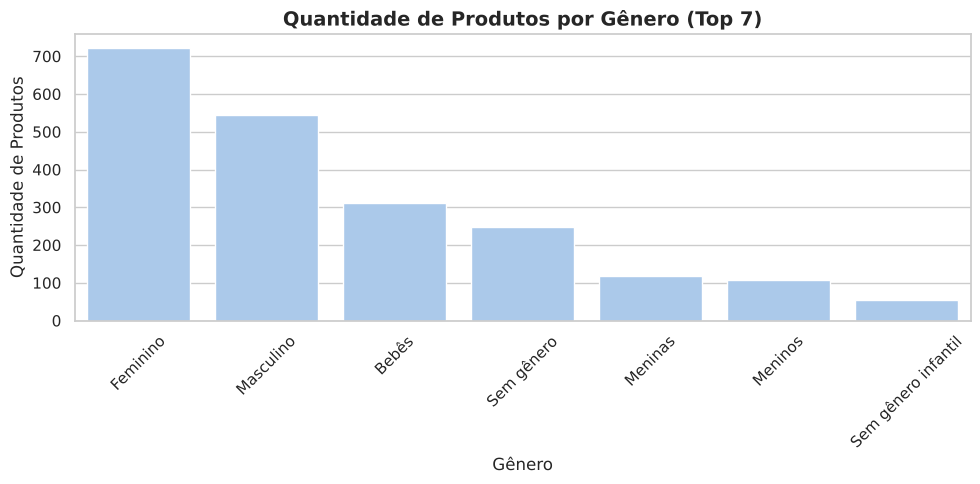

In [11]:
# Contagem de produtos nas 7 categorias de gênero mais frequentes
categoria_genero = df['Gênero'].value_counts().head(7)

plt.figure(figsize=(10, 5))
sns.barplot(x=categoria_genero.index, y=categoria_genero.values)
plt.xticks(rotation=45)
configurar_eixos('Quantidade de Produtos por Gênero (Top 7)', 'Gênero', 'Quantidade de Produtos')

O catálogo é dominado por produtos femininos (723) e masculinos (545), seguidos pela linha de bebês (311).

## 5. Pizza — produtos por material

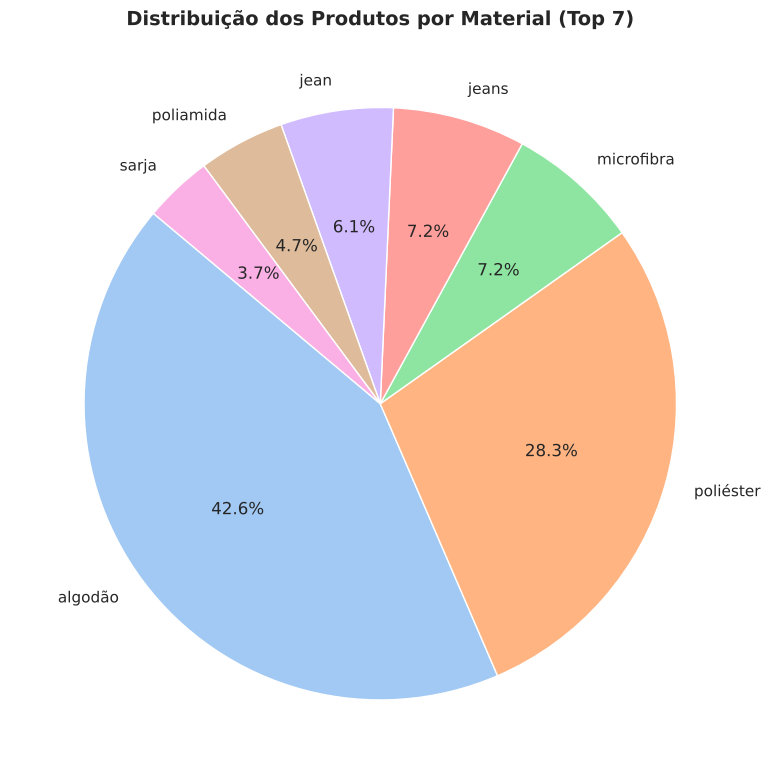

In [12]:
# Participação percentual dos 7 materiais mais frequentes
categoria_material = df['Material'].value_counts().head(7)

plt.figure(figsize=(8, 8))
plt.pie(categoria_material, labels=categoria_material.index, autopct='%1.1f%%', startangle=140)
configurar_eixos('Distribuição dos Produtos por Material (Top 7)')

Algodão e poliéster somam a maior parte dos produtos. Obs.: 'jeans' e 'jean' aparecem separados por diferença de grafia na base — juntos seriam o terceiro material mais comum.

## 6. Densidade — notas dos produtos

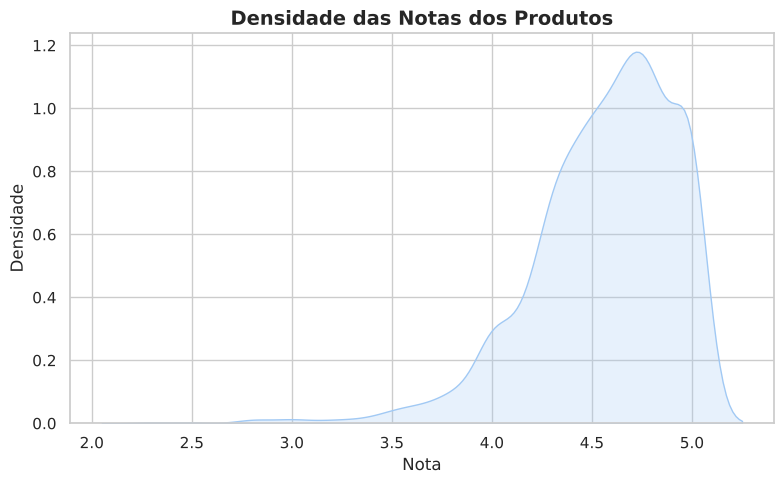

In [13]:
# Curva de densidade das notas (KDE): mostra a forma da distribuição
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='Nota', fill=True)
configurar_eixos('Densidade das Notas dos Produtos', 'Nota', 'Densidade')

As notas se concentram entre 4,4 e 4,8, com poucos produtos abaixo de 4 — a avaliação dos clientes é majoritariamente positiva.

## 7. Regressão — avaliações × quantidade vendida

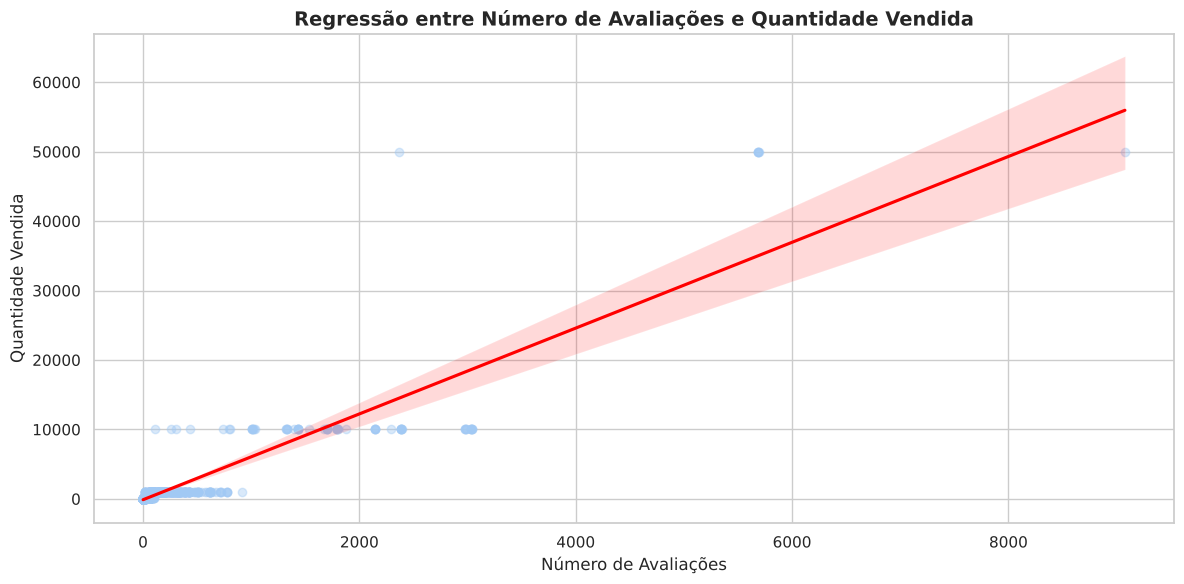

In [14]:
# Regressão linear: quantifica a relação mais forte encontrada no mapa de calor
plt.figure(figsize=(12, 6))
sns.regplot(data=df, x='N_Avaliações', y='Qtd_Vendidos_Cod', scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
configurar_eixos('Regressão entre Número de Avaliações e Quantidade Vendida', 'Número de Avaliações', 'Quantidade Vendida')

A reta confirma a relação positiva: produtos com mais avaliações vendem mais — faz sentido, já que só avalia quem comprou.

## Conclusões
- Preço não explica o volume de vendas; o número de avaliações é o melhor indicador de vendas (r = 0,90).
- O catálogo concentra produtos femininos/masculinos de algodão e poliéster, na faixa de R$ 50–140.
- As notas são altas e pouco variáveis, o que limita seu uso para diferenciar produtos.